In [1]:
import pandas as pd

df = pd.read_csv( r"data\raw\news.csv")
print(df.shape)
print(df.dtypes)
print(df.head(10).to_string())
print(df.isna().mean())              # share of missing values per column
print(df["source"].value_counts())   # adjust to your column name
print(df.duplicated(subset=["url"]).sum())

(6140, 9)
id               int64
source          object
url             object
published_at    object
title           object
summary         object
text            object
section         object
collected_at    object
dtype: object
[10 example rows removed before publishing: they contained full article text, which we may not share]
id              0.000000
source          0.000000
url             0.000000
published_at    0.000000
title           0.000000
summary         0.000489
text            0.460586
section         0.000000
collected_at    0.000000
dtype: float64
source
guardian     3312
nyt          2688
aljazeera      61
bbc            33
foxnews        31
npr            15
Name: count, dtype: int64
0


In [ ]:
import html
import re
from pathlib import Path

import pandas as pd

RAW = Path()
OUT = Path()
MIN_FULLTEXT_CHARS = 500


def clean_text(s):
    if pd.isna(s):
        return None
    s = html.unescape(str(s))
    s = re.sub(r"<[^>]+>", " ", s)       # leftover HTML tags
    s = re.sub(r"\s+", " ", s).strip()
    return s or None


def clean_title(t):
    t = clean_text(t)
    if t is None:
        return None
    return t.split(" | ")[0].strip()      # Guardian opinion pieces: "Title | Author"


def norm_key(t):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", "", t.lower())).strip()


def main():
    df = pd.read_csv(RAW)
    n0 = len(df)

    df["article_id"] = df["source"].str.lower() + "_" + df["id"].astype(str)
    df["source"] = df["source"].str.lower().str.strip()
    df["published_at"] = pd.to_datetime(df["published_at"], utc=True, errors="coerce")
    df["collected_at"] = pd.to_datetime(df["collected_at"], utc=True, errors="coerce")

    df["title_clean"] = df["title"].map(clean_title)
    df["summary"] = df["summary"].map(clean_text)
    df["text"] = df["text"].map(clean_text)
    df["has_fulltext"] = df["text"].str.len().fillna(0) >= MIN_FULLTEXT_CHARS

    df = df.dropna(subset=["title_clean", "published_at"])
    df = df.drop_duplicates(subset="url")
    df["title_key"] = df["title_clean"].map(norm_key)
    df = df.drop_duplicates(subset=["source", "title_key"])

    cols = ["article_id", "source", "url", "published_at", "collected_at",
            "section", "title", "title_clean", "summary", "text", "has_fulltext"]
    df = df[cols].sort_values("published_at", ascending=False).reset_index(drop=True)

    OUT.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(OUT, index=False)

    print(f"rows: {n0} -> {len(df)}")
    print(df.groupby("source").agg(n=("article_id", "size"),
                                   fulltext=("has_fulltext", "sum"),
                                   first=("published_at", "min"),
                                   last=("published_at", "max")))
    print(df["section"].value_counts().head(15))


if __name__ == "__main__":
    main()

rows: 6140 -> 6136
              n  fulltext                     first                      last
source                                                                       
aljazeera    61         0 2026-10-17 08:04:35+00:00 2026-10-18 09:22:44+00:00
bbc          33         0 2026-10-15 17:31:37+00:00 2026-10-18 09:56:45+00:00
foxnews      31         0 2026-10-11 21:56:55+00:00 2026-10-18 05:41:10+00:00
guardian   3312      3306 2026-08-31 02:21:29+00:00 2026-10-18 12:00:03+00:00
npr          15         0 2026-10-15 11:31:25+00:00 2026-10-18 07:56:08+00:00
nyt        2684         0 2026-09-01 00:00:45+00:00 2026-10-18 09:45:19+00:00
section
U.S.           1170
US news         927
World news      798
World           794
Business        781
Politics        347
UK news         311
Environment     304
Technology      290
Science         179
world           140
Climate          81
Health           14
Name: count, dtype: int64


In [3]:
import pandas as pd
import numpy as np
import re

# Check your dataset
print("Dataset shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Dataset shape: (6140, 9)
['id', 'source', 'url', 'published_at', 'title', 'summary', 'text', 'section', 'collected_at']


,id,source,url,published_at,title,summary,text,section,collected_at
0,11085,guardian,https://www.theguardian.com/environment/2026/o...,2026-10-18T12:00:03Z,EPA quietly backtracks on claims US has phased...,Agency changes wording on website as Texas-bas...,The Environmental Protection Agency has quietl...,Environment,2026-10-18 12:26:58
1,11082,guardian,https://www.theguardian.com/business/2026/oct/...,2026-10-18T12:00:02Z,Small business owners are doing OK – but will ...,"Overall, economic sentiment for Trump is poor,...",There are 34m small businesses in the United S...,Business,2026-10-18 12:26:58
2,11083,guardian,https://www.theguardian.com/us-news/2026/oct/1...,2026-10-18T12:00:02Z,Some conservative states aren’t using Medicaid...,States like Missouri and Iowa are choosing to ...,Some conservative states that have rejected ha...,US news,2026-10-18 12:26:58
3,11084,guardian,https://www.theguardian.com/environment/2026/o...,2026-10-18T12:00:02Z,US workers facing deadly heat borrow from toma...,As efforts to protect people from extreme heat...,“It’s the kind of heat that makes you feel lik...,Environment,2026-10-18 12:26:58
4,11081,guardian,https://www.theguardian.com/business/2026/oct/...,2026-10-18T11:46:50Z,World leaders must wise up to threat of cyber-...,Global cooperation seems unlikely despite AI i...,Rogue French fridges were an unlikely talking ...,Business,2026-10-18 12:26:58


In [4]:
# Clean text fields
text_columns = ["title", "summary", "text", "source", "section"]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str)
    df[col] = df[col].apply(
        lambda x: re.sub(r"\s+", " ", x).strip()
    )

# Convert publication date
df["published_at"] = pd.to_datetime(
    df["published_at"], errors="coerce", utc=True
)

# Create analysis text from all available article content
df["analysis_text"] = (
    df["title"] + ". " +
    df["summary"] + ". " +
    df["text"]
).str.strip()

# Useful date fields for dashboard filters
df["published_date"] = df["published_at"].dt.date
df["year_month"] = df["published_at"].dt.to_period("M").astype(str)

display(df[["title", "published_at", "analysis_text"]].head())

<cell>:24: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["year_month"] = df["published_at"].dt.to_period("M").astype(str)


,title,published_at,analysis_text
0,EPA quietly backtracks on claims US has phased...,2026-10-18 12:00:03+00:00,EPA quietly backtracks on claims US has phased...
1,Small business owners are doing OK – but will ...,2026-10-18 12:00:02+00:00,Small business owners are doing OK – but will ...
2,Some conservative states aren’t using Medicaid...,2026-10-18 12:00:02+00:00,Some conservative states aren’t using Medicaid...
3,US workers facing deadly heat borrow from toma...,2026-10-18 12:00:02+00:00,US workers facing deadly heat borrow from toma...
4,World leaders must wise up to threat of cyber-...,2026-10-18 11:46:50+00:00,World leaders must wise up to threat of cyber-...


In [ ]:
# Run once if you have not installed it:


from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

scores = df["analysis_text"].apply(analyzer.polarity_scores)

df["sentiment_score"] = scores.apply(lambda x: x["compound"])

df["sentiment"] = df["sentiment_score"].apply(
    lambda score: (
        "positive" if score >= 0.05
        else "negative" if score <= -0.05
        else "neutral"
    )
)

display(df[["title", "sentiment", "sentiment_score"]].head(10))

,title,sentiment,sentiment_score
0,EPA quietly backtracks on claims US has phased...,negative,-0.8733
1,Small business owners are doing OK – but will ...,positive,0.9988
2,Some conservative states aren’t using Medicaid...,negative,-0.8162
3,US workers facing deadly heat borrow from toma...,positive,0.9802
4,World leaders must wise up to threat of cyber-...,negative,-0.9897
5,Pope Leo to gradually resume papal activities ...,positive,0.9377
6,A California town’s beaches are washing away. ...,negative,-0.9952
7,‘Damp squib’: Ed Davey can breathe easy as Lib...,positive,0.9879
8,The problem with telling people the world is e...,negative,-0.9992
9,Margaret Hamilton obituary,positive,0.9959


: 

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

labelled_df = df[
    (df["analysis_text"].str.len() > 30) &
    (df["section"].str.strip() != "")
].copy()

# Remove classes with too few examples for a stratified split
counts = labelled_df["section"].value_counts()
labelled_df = labelled_df[
    labelled_df["section"].isin(counts[counts >= 2].index)
]

X_train, X_test, y_train, y_test = train_test_split(
    labelled_df["analysis_text"],
    labelled_df["section"],
    test_size=0.2,
    random_state=42,
    stratify=labelled_df["section"]
)

topic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

topic_model.fit(X_train, y_train)

predictions = topic_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Macro F1:", round(
    f1_score(y_test, predictions, average="macro", zero_division=0), 3
))
print(classification_report(y_test, predictions, zero_division=0))

Accuracy: 0.769
Macro F1: 0.645
              precision    recall  f1-score   support

    Business       0.78      0.65      0.71       156
     Climate       0.50      0.25      0.33        16
 Environment       0.69      0.89      0.78        61
      Health       0.00      0.00      0.00         3
    Politics       0.73      0.86      0.79        69
     Science       0.59      0.64      0.61        36
  Technology       0.72      0.86      0.79        58
        U.S.       0.79      0.84      0.81       235
     UK news       0.66      0.79      0.72        62
     US news       0.93      0.89      0.91       185
       World       0.69      0.72      0.71       159
  World news       0.91      0.71      0.80       160
       world       0.44      0.43      0.44        28

    accuracy                           0.77      1228
   macro avg       0.65      0.66      0.65      1228
weighted avg       0.77      0.77      0.77      1228



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Use a subset initially to test performance
sample = df[df["analysis_text"].str.len() > 30].copy()

vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

matrix = vectorizer.fit_transform(sample["analysis_text"])

# Similarity of the first article to every other article
similarities = cosine_similarity(matrix[0], matrix).flatten()
similarities[0] = -1

top_indices = similarities.argsort()[-5:][::-1]

display(sample.iloc[top_indices][["title", "source", "published_at"]])

,title,source,published_at
3682,US environment agency let Bayer pick regulatio...,guardian,2026-09-20 12:00:14+00:00
2525,EPA union sues Trump administration to restore...,guardian,2026-09-29 16:28:31+00:00
2684,‘Are these chemicals in my blood?’ How one com...,guardian,2026-09-28 14:54:50+00:00
4400,US ends limits on coal and gas plant emissions...,guardian,2026-09-14 21:17:19+00:00
2846,New research finds 485 chemicals in US pestici...,guardian,2026-09-26 13:00:36+00:00


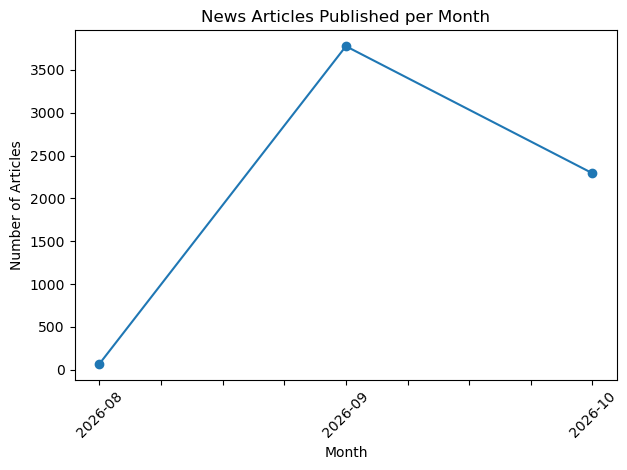

In [ ]:
import matplotlib.pyplot as plt

# Number of articles published per month
monthly_counts = df.groupby("year_month").size()

monthly_counts.plot(kind="line", marker="o")
plt.title("News Articles Published per Month")
plt.xlabel("Month")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

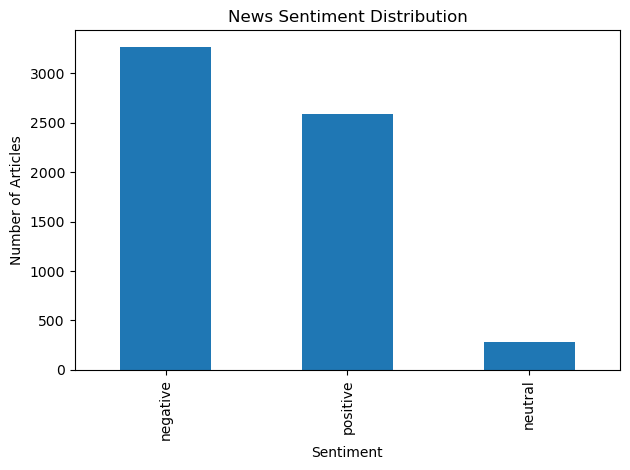

In [ ]:
df["sentiment"].value_counts().plot(kind="bar")
plt.title("News Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import normalize

# Work on a copy of your existing dataframe
df = df.copy().reset_index(drop=True)

for col in ["title", "summary", "text", "source"]:
    if col not in df.columns:
        df[col] = ""
    df[col] = df[col].fillna("").astype(str)

# Titles and summaries often capture the main event concisely.
# A short excerpt of the full text adds context.
df["cluster_input"] = (
    "Title: " + df["title"] +
    " Summary: " + df["summary"] +
    " Article: " + df["text"].str.slice(0, 500)
).str.strip()

# Load an English semantic embedding model
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

embeddings = embedding_model.encode(
    df["cluster_input"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

# Group similar articles
# cosine distance = 1 - cosine similarity
clusterer = DBSCAN(
    eps=0.25,
    min_samples=2,
    metric="cosine"
)

df["cluster_id"] = clusterer.fit_predict(embeddings)

print("Articles:", len(df))
print("Clusters found:", df.loc[df["cluster_id"] != -1, "cluster_id"].nunique())
print("Articles not assigned to a cluster:", (df["cluster_id"] == -1).sum())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/192 [00:00<?, ?it/s]

Articles: 6140
Clusters found: 485
Articles not assigned to a cluster: 4239


In [ ]:
cluster_overview = (
    df[df["cluster_id"] != -1]
    .groupby("cluster_id")
    .agg(
        article_count=("title", "size"),
        sources=("source", lambda x: sorted(set(x))),
        headlines=("title", lambda x: list(x.head(5)))
    )
    .sort_values("article_count", ascending=False)
    .reset_index()
)

display(cluster_overview.head(20))

,cluster_id,article_count,sources,headlines
0,3,89,"[aljazeera, foxnews, guardian, nyt]",[Fighting intensifies across Yemen as humanita...
1,16,81,"[aljazeera, bbc, foxnews, guardian, npr, nyt]",[Zelenskyy urges support for new US sanctions ...
2,117,38,"[guardian, nyt]",[Christa Pike out of hospital and back in pris...
3,175,31,"[guardian, nyt]",[State parliament elects Germany’s first far-r...
4,2,30,"[aljazeera, bbc, guardian, npr, nyt]",[Burnt out cars and shattered glass on Paris s...
5,45,27,"[guardian, nyt]",[Clancy Trial’s Holdout Juror Says That the De...
6,103,23,"[guardian, nyt]",[Melbourne Islamic leader rejects centre’s all...
7,82,23,"[guardian, nyt]",[Judge extends White House access to banned me...
8,300,20,"[guardian, nyt]",[Nepal’s PM says flash flood was ‘warning to w...
9,94,20,"[guardian, nyt]",[How Two Crypto Billionaires Are Making Britis...


In [ ]:
cluster_to_inspect = 0

display(
    df.loc[
        df["cluster_id"] == cluster_to_inspect,
        ["source", "published_at", "title", "summary", "url"]
    ].sort_values("published_at")
)

,source,published_at,title,summary,url
982,nyt,2026-10-11 12:55:54+00:00,Pope Leo Will Have Surgery to Remove Growth on...,A recent medical examination found a small nod...,https://www.nytimes.com/2026/10/11/world/europ...
795,nyt,2026-10-13 11:19:11+00:00,Pope Leo Found to Have Lung Cancer During Surg...,The surgeons removed the lower lobe of the pop...,https://www.nytimes.com/2026/10/13/world/europ...
781,foxnews,2026-10-13 13:24:55+00:00,Pope Leo diagnosed with lung cancer after surg...,Pope Leo XIV arrived at Gemelli Hospital in Ro...,https://www.foxnews.com/world/pope-leo-diagnos...
734,guardian,2026-10-13 20:32:36+00:00,Pope Leo diagnosed with lung cancer as growth ...,Vatican says pontiff had lower lobe of right l...,https://www.theguardian.com/world/2026/oct/13/...
703,nyt,2026-10-14 02:30:29+00:00,Leo XIV’s Cancer Diagnosis Tests the Assumptio...,For a pope who appeared to have time on his si...,https://www.nytimes.com/2026/10/13/world/europ...
701,nyt,2026-10-14 02:46:26+00:00,Pope Leo’s Cancer Surgery Draws Outpouring Fro...,The pontiff’s illness also prompted calls for ...,https://www.nytimes.com/2026/10/13/world/europ...
661,nyt,2026-10-14 09:32:46+00:00,Pope Leo’s Lung Cancer Diagnosis: What to Know,Pope Leo XIV has a common form of the disease....,https://www.nytimes.com/2026/10/14/world/europ...
656,guardian,2026-10-14 10:15:14+00:00,Pope Leo recovering from surgery after lung ca...,Vatican says operation on US-born head of Roma...,https://www.theguardian.com/us-news/2026/oct/1...
649,nyt,2026-10-14 11:36:00+00:00,Posters and Prayers for Pope Leo at Rome Hospi...,"The pontiff, 71, is expected to spend about a ...",https://www.nytimes.com/2026/10/14/world/europ...
611,nyt,2026-10-14 15:46:17+00:00,A New World of Lung Cancer Therapy Awaits Pope...,Lung cancer is still a leading cause of cancer...,https://www.nytimes.com/2026/10/14/science/pop...


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores = analyzer.polarity_scores(text)
    compound = scores["compound"]

    if compound >= 0.05:
        label = "positive"
    elif compound <= -0.05:
        label = "negative"
    else:
        label = "neutral"

    return pd.Series({
        "sentiment": label,
        "sentiment_score": compound,
        "positive_score": scores["pos"],
        "neutral_score": scores["neu"],
        "negative_score": scores["neg"]
    })

sentiment_results = df["cluster_input"].apply(get_sentiment)
df[sentiment_results.columns] = sentiment_results

display(
    df[["cluster_id", "source", "title", "sentiment", "sentiment_score"]]
    .head(20)
)

,cluster_id,source,title,sentiment,sentiment_score
0,-1,guardian,EPA quietly backtracks on claims US has phased...,negative,-0.6240
1,-1,guardian,Small business owners are doing OK – but will ...,positive,0.9310
2,-1,guardian,Some conservative states aren’t using Medicaid...,negative,-0.2023
3,-1,guardian,US workers facing deadly heat borrow from toma...,positive,0.4804
4,-1,guardian,World leaders must wise up to threat of cyber-...,negative,-0.6369
5,0,guardian,Pope Leo to gradually resume papal activities ...,positive,0.7964
6,-1,guardian,A California town’s beaches are washing away. ...,negative,-0.7227
7,-1,guardian,‘Damp squib’: Ed Davey can breathe easy as Lib...,negative,-0.8312
8,-1,guardian,The problem with telling people the world is e...,negative,-0.9161
9,-1,guardian,Margaret Hamilton obituary,negative,-0.5267


In [ ]:
cluster_sentiment = (
    df[df["cluster_id"] != -1]
    .groupby(["cluster_id", "source", "sentiment"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(cluster_sentiment.head(30))

sentiment,cluster_id,source,negative,neutral,positive
0,0,bbc,1,0,0
1,0,foxnews,3,0,0
2,0,guardian,5,0,1
3,0,npr,1,0,0
4,0,nyt,7,1,1
5,1,guardian,8,0,7
6,2,aljazeera,3,0,0
7,2,bbc,3,0,0
8,2,guardian,10,0,2
9,2,npr,1,0,0


In [ ]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display
import ipywidgets as widgets

# Use your existing DataFrame: df
viz = df.copy()

# Ensure expected columns exist
for col in ["source", "title", "sentiment", "political_framing"]:
    if col not in viz.columns:
        viz[col] = "unknown"

if "cluster_id" not in viz.columns:
    raise ValueError("Run the clustering step first to create df['cluster_id'].")

viz["cluster_id"] = pd.to_numeric(viz["cluster_id"], errors="coerce")
viz["source"] = viz["source"].fillna("Unknown")
viz["sentiment"] = viz["sentiment"].fillna("unknown")
viz["political_framing"] = viz["political_framing"].fillna("not analyzed")

# Exclude unclustered articles from event-cluster visualizations
clustered = viz[viz["cluster_id"].notna() & (viz["cluster_id"] != -1)].copy()
clustered["cluster_id"] = clustered["cluster_id"].astype(int)

# -------------------------------
# A. Dashboard overview
# -------------------------------
print(f"Total articles: {len(viz):,}")
print(f"Event clusters: {clustered['cluster_id'].nunique():,}")
print(f"Articles not assigned to a cluster: {(viz['cluster_id'] == -1).sum():,}")

# -------------------------------
# B. Largest news event clusters
# -------------------------------
if not clustered.empty:
    cluster_counts = (
        clustered.groupby("cluster_id")
        .size()
        .sort_values(ascending=False)
        .head(20)
        .rename("article_count")
        .reset_index()
    )

    cluster_counts["cluster"] = (
        "Event " + cluster_counts["cluster_id"].astype(str)
    )

    fig = px.bar(
        cluster_counts.sort_values("article_count"),
        x="article_count",
        y="cluster",
        orientation="h",
        title="Top 20 News Event Clusters",
        labels={
            "article_count": "Number of articles",
            "cluster": "News cluster"
        },
        hover_data=["cluster_id"]
    )
    fig.show()

# -------------------------------
# C. Overall sentiment distribution
# -------------------------------
sentiment_counts = (
    viz["sentiment"].value_counts()
    .rename_axis("sentiment")
    .reset_index(name="articles")
)

fig = px.pie(
    sentiment_counts,
    names="sentiment",
    values="articles",
    hole=0.45,
    title="Sentiment Across All News Articles"
)
fig.show()

# -------------------------------
# D. Sentiment by news outlet
# -------------------------------
source_sentiment = (
    viz.groupby(["source", "sentiment"])
    .size()
    .reset_index(name="articles")
)

fig = px.bar(
    source_sentiment,
    x="source",
    y="articles",
    color="sentiment",
    barmode="stack",
    title="Sentiment by News Outlet",
    labels={"source": "News outlet", "articles": "Articles"}
)
fig.update_layout(xaxis_tickangle=-35)
fig.show()

# -------------------------------
# E. Estimated political framing by outlet
# -------------------------------
framing_data = viz[
    ~viz["political_framing"].isin(["not analyzed", "unknown", ""])
]

if not framing_data.empty:
    framing_counts = (
        framing_data.groupby(["source", "political_framing"])
        .size()
        .reset_index(name="articles")
    )

    fig = px.bar(
        framing_counts,
        x="source",
        y="articles",
        color="political_framing",
        barmode="stack",
        title="Estimated Political Framing by News Outlet",
        labels={
            "source": "News outlet",
            "articles": "Articles",
            "political_framing": "Predicted framing"
        }
    )
    fig.update_layout(xaxis_tickangle=-35)
    fig.show()
else:
    print("No political framing results yet. Run the framing model first.")

# -------------------------------
# F. Inspect articles within an event
# -------------------------------
if not clustered.empty:
    cluster_options = sorted(clustered["cluster_id"].unique())
    cluster_picker = widgets.Dropdown(
        options=cluster_options,
        description="Event:",
        layout=widgets.Layout(width="350px")
    )

    def show_event(cluster_id):
        event = clustered[clustered["cluster_id"] == cluster_id]

        display(event[
            [
                c for c in [
                    "source", "published_at", "title",
                    "sentiment", "sentiment_score",
                    "political_framing", "url"
                ]
                if c in event.columns
            ]
        ].reset_index(drop=True))

    display(widgets.interactive(
        show_event,
        cluster_id=cluster_picker
    ))


Total articles: 6,140
Event clusters: 485
Articles not assigned to a cluster: 4,239


No political framing results yet. Run the framing model first.


interactive(children=(Dropdown(description='Event:', layout=Layout(width='350px'), options=(np.int64(0), np.in…

In [ ]:

import plotly.express as px

sentiment_by_cluster = (
    news.groupby(["cluster_id", "sentiment"])
    .size()
    .reset_index(name="article_count")
)

# Show the 20 largest clusters
top_clusters = (
    news["cluster_id"].value_counts().head(20).index
)

plot_data = sentiment_by_cluster[
    sentiment_by_cluster["cluster_id"].isin(top_clusters)
].copy()

plot_data["cluster"] = "Event " + plot_data["cluster_id"].astype(str)

fig = px.bar(
    plot_data,
    x="cluster",
    y="article_count",
    color="sentiment",
    barmode="stack",
    title="Sentiment of Coverage Within Each News Event",
    labels={
        "cluster": "News event",
        "article_count": "Number of articles",
        "sentiment": "Sentiment"
    },
    hover_data=["cluster_id"]
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()
